In [1]:
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
num_agent = 5
random_seed = 0

num_trained_model = 5
train_seed = 0

In [17]:
model_name = "target135d"

In [18]:
folder = f"NUM_AGENT{str(num_agent).zfill(2)}{model_name}/{str(train_seed).zfill(4)}/"

reward_csv = folder + f"reward_output/reward_history-NUM_AGENT{str(num_agent).zfill(2)}-Random_seed{str(train_seed).zfill(4)}.csv"
distance_csv = folder + f"distance_output/total_distance_list-NUM_AGENT{str(num_agent).zfill(2)}-Random_seed{str(train_seed).zfill(4)}.csv"
trajectory_csv = folder + f"greedy_output/check_position_heading-NUM_AGENT{str(num_agent).zfill(2)}-Random_seed{str(random_seed).zfill(4)}-NUMBER_OF_AGENT_TRAINED_MODEL{str(num_trained_model).zfill(2)}-Random_seed_trained_model{str(train_seed).zfill(4)}.csv"


<AxesSubplot:>

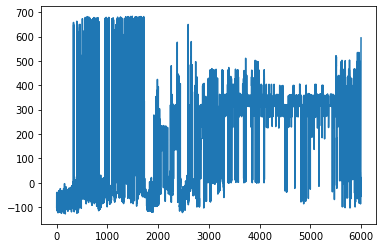

In [19]:
df_reward = pd.read_csv(reward_csv, header=None)
df_reward.loc[0, :].plot()

Fixed initial position
success rate: 0.9489795918367347
up rate: 0.6881720430107527
low rate: 0.3118279569892473


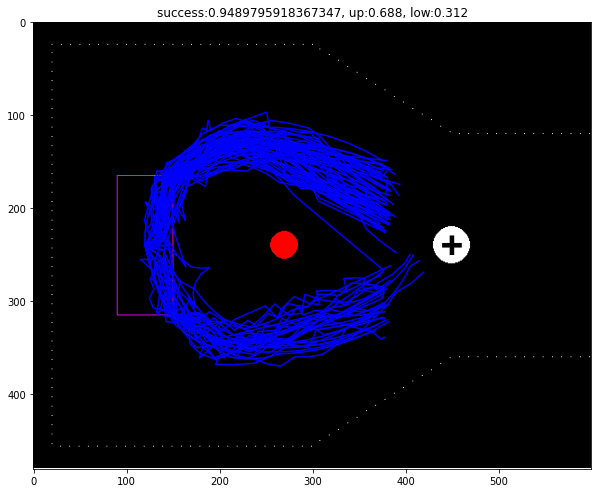

In [21]:
# plot the trajectories of the box with all random seeds
from scripts.pygame_env import CustomEnv
import pygame
import numpy as np

env = CustomEnv(random_initialization=False, n_agents=5)
env.render()

plt.figure(figsize=[10, 10])
background = np.transpose(
        np.array(pygame.surfarray.pixels3d(env.screen)), axes=(1, 0, 2)
    )
plt.imshow(background)

pygame.quit()

count_success = 0
count_up = 0
count_low = 0
total_num = 100

for train_seed in range(total_num):
    folder = f"NUM_AGENT{str(num_agent).zfill(2)}{model_name}/{str(train_seed).zfill(4)}/"
    trajectory_csv = folder + f"greedy_output/check_position_heading-NUM_AGENT{str(num_agent).zfill(2)}-Random_seed{str(random_seed).zfill(4)}-NUMBER_OF_AGENT_TRAINED_MODEL{str(num_trained_model).zfill(2)}-Random_seed_trained_model{str(train_seed).zfill(4)}.csv"
    success_csv = folder + f"greedy_output/check_success-NUM_AGENT{str(num_agent).zfill(2)}-Random_seed{str(random_seed).zfill(4)}-NUMBER_OF_AGENT_TRAINED_MODEL{str(num_trained_model).zfill(2)}-Random_seed_trained_model{str(train_seed).zfill(4)}.csv"
    
    # check success rate
    df_success = pd.read_csv(success_csv, header=None)
    if df_success.loc[0, 0] < 1:
        continue
    count_success += 1
    
    df_trajectory = pd.read_csv(trajectory_csv, header=None)
    x = df_trajectory.loc[:, 1].to_numpy()
    y = df_trajectory.loc[:, 2].to_numpy()
    plt.plot(x, y, "b")
    
    if min(y) > 200:
        count_low += 1
    else:
        count_up += 1
        
print(f"success rate: {count_success/total_num}")
print(f"up rate: {count_up/count_success}")
print(f"low rate: {count_low/count_success}")

plt.title(f"success:{count_success/total_num}, up:{count_up/count_success :.3f}, low:{count_low/count_success :.3f}")
plt.ylim([background.shape[0], 0])
import os
if not os.path.exists("plots"):
    os.makedirs("plots")
plt.savefig(f"plots/NUM_AGENT{str(num_agent).zfill(2)}{model_name}-Random_seed{str(random_seed).zfill(4)}-NUMBER_OF_AGENT_TRAINED_MODEL{str(num_trained_model).zfill(2)}.png",
           facecolor="white")

Fixed initial position


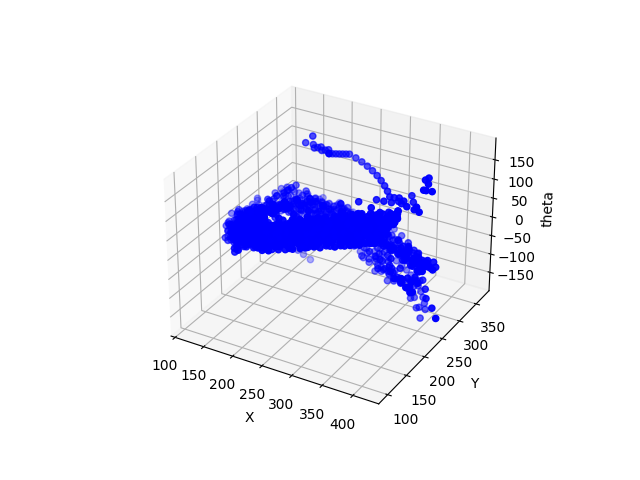

success rate: 0.9489795918367347
up rate: 0.6881720430107527
low rate: 0.3118279569892473


In [33]:
# plot the trajectories of the box with all random seeds in 3D space
from scripts.pygame_env import CustomEnv
import pygame
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

%matplotlib widget

env = CustomEnv(random_initialization=False, n_agents=5)
env.render()

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# background = np.transpose(
#         np.array(pygame.surfarray.pixels3d(env.screen)), axes=(1, 0, 2)
#     )
# plt.imshow(background)

pygame.quit()

count_success = 0
count_up = 0
count_low = 0
total_num = 98

for train_seed in range(total_num):
    folder = f"NUM_AGENT{str(num_agent).zfill(2)}{model_name}/{str(train_seed).zfill(4)}/"
    trajectory_csv = folder + f"greedy_output/check_position_heading-NUM_AGENT{str(num_agent).zfill(2)}-Random_seed{str(random_seed).zfill(4)}-NUMBER_OF_AGENT_TRAINED_MODEL{str(num_trained_model).zfill(2)}-Random_seed_trained_model{str(train_seed).zfill(4)}.csv"
    success_csv = folder + f"greedy_output/check_success-NUM_AGENT{str(num_agent).zfill(2)}-Random_seed{str(random_seed).zfill(4)}-NUMBER_OF_AGENT_TRAINED_MODEL{str(num_trained_model).zfill(2)}-Random_seed_trained_model{str(train_seed).zfill(4)}.csv"
    
    # check success rate
    df_success = pd.read_csv(success_csv, header=None)
    if df_success.loc[0, 0] < 1:
        continue
    count_success += 1
    
    df_trajectory = pd.read_csv(trajectory_csv, header=None)
    x = df_trajectory.loc[:, 1].to_numpy()
    y = df_trajectory.loc[:, 2].to_numpy()
    theta = df_trajectory.loc[:, 3].to_numpy()
    
    
    # Create the 3D scatter plot
    scatter = ax.scatter(x, y, theta, c='b', marker='o')
    
    if min(y) > 200:
        count_low += 1
    else:
        count_up += 1
       
# Set labels
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('theta')

plt.show()
    
print(f"success rate: {count_success/total_num}")
print(f"up rate: {count_up/count_success}")
print(f"low rate: {count_low/count_success}")

# plt.title(f"success:{count_success/total_num}, up:{count_up/count_success :.3f}, low:{count_low/count_success :.3f}")
# plt.ylim([background.shape[0], 0])
# import os
# if not os.path.exists("plots"):
#     os.makedirs("plots")
# plt.savefig(f"plots/NUM_AGENT{str(num_agent).zfill(2)}{model_name}-Random_seed{str(random_seed).zfill(4)}-NUMBER_OF_AGENT_TRAINED_MODEL{str(num_trained_model).zfill(2)}.png",
#            facecolor="white")

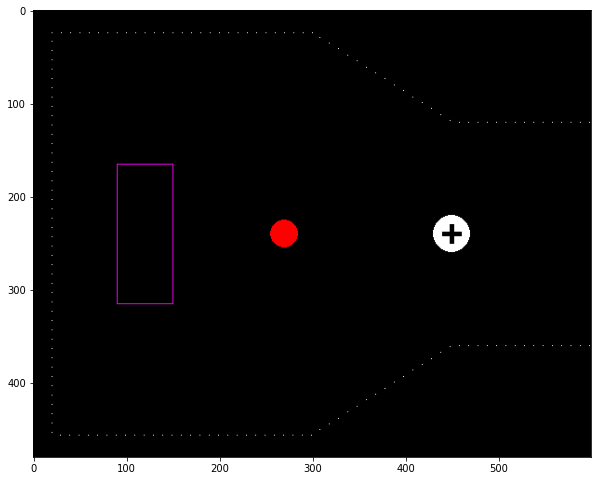

In [59]:
from scripts.pygame_env import CustomEnv
import pygame

env = CustomEnv(random_initialization=False, n_agents=5)
env.render()

plt.figure(figsize=[10, 10])
plt.imshow(np.transpose(
        np.array(pygame.surfarray.pixels3d(env.screen)), axes=(1, 0, 2)
    ))

pygame.quit()
# cv2.imwrite("test.png", np.transpose(
#         np.array(pygame.surfarray.pixels3d(env.screen)), axes=(1, 0, 2)
#     ))